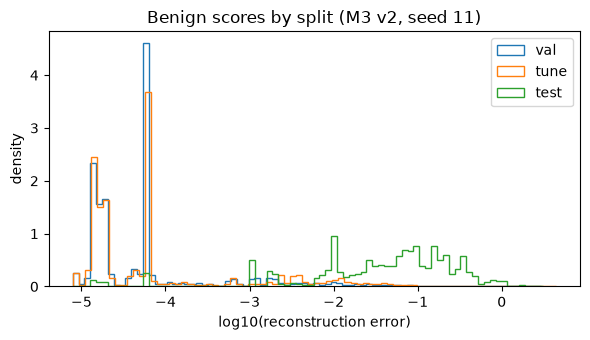

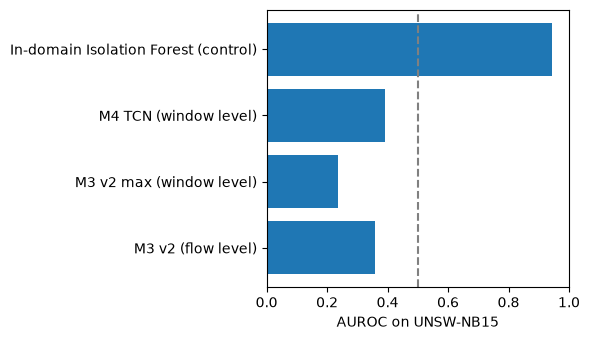

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent
FIG = ROOT / "report" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(ROOT / "results" / "scores" / "m3v2_autoencoder_nftoniot_seed11.parquet")
b = df[df["label"] == 0]
fig, ax = plt.subplots(figsize=(6, 3.5))
for sp in ["val", "tune", "test"]:
    ax.hist(np.log10(b[b["split"] == sp]["score"] + 1e-6), bins=80, histtype="step", density=True, label=sp)
ax.set_xlabel("log10(reconstruction error)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Benign scores by split (M3 v2, seed 11)")
fig.tight_layout(); fig.savefig(FIG / "fig1_benign_scores.png", dpi=200)

c = pd.read_csv(ROOT / "results" / "cross_dataset_unsw.csv")
labels = list(c["model"]) + ["In-domain Isolation Forest (control)"]
vals = list(c["auroc"]) + [0.943]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(labels, vals); ax.axvline(0.5, ls="--", c="gray")
ax.set_xlabel("AUROC on UNSW-NB15"); ax.set_xlim(0, 1)
fig.tight_layout(); fig.savefig(FIG / "fig4_cross_dataset.png", dpi=200)